In [4]:
import pandas as pd
import pickle
from sklearn.linear_model import LogisticRegression

# ----------------------------
# Load X_train_vec
# ----------------------------
with open("X_train_vec.pkl", "rb") as f:
    X_train_vec = pickle.load(f)

# ----------------------------
# Load y_train
# ----------------------------
y_train = pd.read_csv("y_train.csv").values.ravel()

assert X_train_vec.shape[0] == len(y_train), "Mismatch X/y"

# ----------------------------
# Train model
# ----------------------------
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

# ----------------------------
# train score
# ----------------------------
print("Train score:", model.score(X_train_vec, y_train))

# ----------------------------
# Save model
# ----------------------------
with open("expense_model.pkl", "wb") as f:
    pickle.dump(model, f)

print("Model classes:", model.classes_)


Train score: 0.9997306276376043
Model classes: ['bills_&_utilities' 'education' 'entertainment' 'food_&_dining'
 'health_&_medical' 'income_&_transfers' 'other' 'shopping'
 'transportation']


Test Accuracy: 0.9819991219083858
                    precision    recall  f1-score   support

 bills_&_utilities       1.00      0.67      0.80       357
         education       1.00      1.00      1.00       516
     entertainment       1.00      1.00      1.00       439
     food_&_dining       1.00      1.00      1.00      1375
  health_&_medical       1.00      1.00      1.00      1117
income_&_transfers       0.83      1.00      0.91       313
             other       0.92      0.99      0.96       672
          shopping       1.00      1.00      1.00      1064
    transportation       1.00      1.00      1.00       980

          accuracy                           0.98      6833
         macro avg       0.97      0.96      0.96      6833
      weighted avg       0.98      0.98      0.98      6833



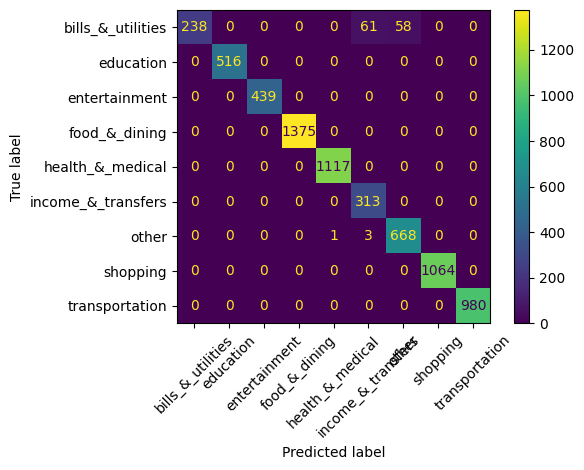

In [5]:
import pandas as pd
import pickle
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

with open("expense_model.pkl", "rb") as f:
    expense_model = pickle.load(f)

with open("X_test_vec.pkl", "rb") as f:
    X_test_vec = pickle.load(f)

y_test = pd.read_csv("y_test.csv").values.ravel()  # نصوص

y_pred = expense_model.predict(X_test_vec)

score = accuracy_score(y_test, y_pred)
print("Test Accuracy:", score)

report = classification_report(y_test, y_pred)
print(report)

cm = confusion_matrix(y_test, y_pred, labels=expense_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=expense_model.classes_)
disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()
disp.figure_.savefig("confusion_matrix.png")

with open("model_results.md", "w", encoding="utf-8") as f:
    f.write("# Model Performance Report\n\n")
    f.write(f"**Accuracy:** {score}\n\n")
    f.write("## Classification Report\n\n")
    f.write(report)
